# Expérience 3 — auto-encodeur variationnel sur CAMUS

Ce notebook reconstruit des coupes d'échocardiographie 2D (jeu CAMUS, images `camus_64`) avec un `AutoencoderKL` de MONAI. Il reprend la graine, le découpage par patient et la normalisation des expériences 1 et 2, et change quatre éléments du protocole pour viser à la fois la fidélité de l'expérience 2 et la structure de l'expérience 1, à un coût CPU proche de cette dernière.

1. **Architecture.** Canaux `(16, 32, 64, 64)`, un bloc résiduel par niveau, `norm_num_groups=16`, sans attention. Le code latent passe à `8×8×8` (512 coefficients, compression ×8). Le nombre de paramètres reste proche de 475 000 : par rapport à l'expérience 1, seul le goulot change.
2. **Reconstruction.** L1 pondérée par le masque expert et SSIM de MONAI. Le masque entre dans la fonction de coût. L'entrée du réseau reste l'image à un canal.
3. **Attribut latent (AR-VAE).** La moyenne spatiale du premier canal de μ est poussée à varier dans le même sens que l'aire de la cavité ventriculaire gauche.
4. **Optimisation.** AdamW, calendrier cosinus, montée linéaire de β sur les cinq premières époques.

L'expérience 1 a été entraînée 25 époques, les expériences 2 et 3 le sont 20. La section 4 rapporte la durée totale et la durée par époque.

| | Expérience 1 | Expérience 2 | Expérience 3 |
| --- | --- | --- | --- |
| Images | `camus_64`, 1 canal, intensités dans [0, 1] | mêmes images, même normalisation | mêmes images, même normalisation |
| Découpage | 80 % / 10 % / 10 % par patient, graine 12345 | même découpage | même découpage |
| Canaux | (16, 32, 64, 64) | (32, 64, 128, 128) | (16, 32, 64, 64) |
| Code latent | 4×8×8, 256 coefficients, compression ×16 | 8×8×8, 512 coefficients, compression ×8 | 8×8×8, 512 coefficients, compression ×8 |
| Paramètres | 473 649 | 1 888 449 | environ 478 000, décompte en section 2 |
| Perte de reconstruction | L1 | MSE | 0,7 L1 pondérée (cœur ×3) + 0,3 SSIM |
| Régularisation latente | β KL, montée de β jusqu'à 1e-4 | β KL, β = 1e-4 constant | β KL, montée linéaire de 0 à 1e-4 sur 5 époques, plus γ L_attr (γ = 1e-3) |
| Optimiseur / calendrier | Adam 1e-3, cosinus | Adam 1e-3, pas constant | AdamW 1e-3, weight decay 1e-5, cosinus jusqu'à 1e-5 |

Quatre étapes : audit des données, architecture, perte et entraînement, évaluation (métriques, comparaison, reconstructions, t-SNE, interpolation ED → ES).

Les poids vont dans `checkpoints/`, le GIF et le fichier de résultats dans `artifacts/`. Ces dossiers sont ignorés par git.

CAMUS doit être cité : S. Leclerc, E. Smistad, J. Pedrosa, A. Ostvik, et al., « Deep Learning for Segmentation using an Open Large-Scale Dataset in 2D Echocardiography », IEEE Transactions on Medical Imaging, vol. 38, n° 9, pp. 2198-2210, 2019, doi: 10.1109/TMI.2019.2900516.


In [1]:
%matplotlib inline

import json
import os
import random
import time
import zipfile
from collections import Counter
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import monai
import nibabel as nib
import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from monai.data import DataLoader
from monai.losses import SSIMLoss
from monai.metrics import PSNRMetric, SSIMMetric
from monai.networks.nets import AutoencoderKL
from monai.utils import set_determinism
from scipy.stats import pearsonr, spearmanr
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset as TorchDataset
from torchinfo import summary

print(f"PyTorch {torch.__version__}  |  MONAI {monai.__version__}  |  NumPy {np.__version__}")


PyTorch 2.15.0+cpu  |  MONAI 1.6.1  |  NumPy 2.5.4


In [2]:
SEED = 12345


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    set_determinism(seed=seed)


set_seed(SEED)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass
torch.set_num_threads(max(1, os.cpu_count() or 1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Périphérique : {device}")
print(f"Fils CPU utilisés par PyTorch : {torch.get_num_threads()}")

CHECKPOINT_DIR = Path("checkpoints")
ARTIFACT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "exp3_vae_best.pth"


Périphérique : cpu
Fils CPU utilisés par PyTorch : 8


## 1. Audit et préparation des données

`data_dir` pointe vers le dossier extrait `camus_64` (images 64×64, un canal). L'ordre de recherche est : la variable `CAMUS_DATA_ROOT` si elle est définie, puis `../camus_64`, puis `data/camus_64`. Si aucun dossier n'existe, le notebook télécharge `camus_64.zip` depuis le serveur du cours.

Chaque examen est une image `uint8`. On divise par 255 pour obtenir des intensités dans [0, 1], communes à tous les patients. Le tableau est transposé pour placer l'apex en haut de la figure. Le masque expert suit la même géométrie.


In [3]:
if os.environ.get("CAMUS_DATA_ROOT"):
    root = Path(os.environ["CAMUS_DATA_ROOT"]).expanduser().resolve()
    data_dir = root if root.name.startswith("camus_") else root / "camus_64"
elif (Path("..") / "camus_64").resolve().is_dir():
    data_dir = (Path("..") / "camus_64").resolve()
elif (Path("data") / "camus_64").resolve().is_dir():
    data_dir = (Path("data") / "camus_64").resolve()
else:
    data_dir = (Path("..") / "camus_64").resolve()

if not data_dir.is_dir():
    zip_url = "https://www.creatis.insa-lyon.fr/~bernard/camus/camus_64.zip"
    print(f"{data_dir} est absent. Téléchargement de {zip_url}")
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(zip_url, timeout=180) as response:
        payload = response.read()
    with zipfile.ZipFile(BytesIO(payload)) as archive:
        archive.extractall(data_dir.parent)
    print(f"Archive extraite dans {data_dir}")
else:
    print(f"Données locales : {data_dir}")

assert data_dir.is_dir(), f"Dossier CAMUS introuvable : {data_dir}"


Données locales : /home/cytech/info/IAV/camus_64


### Découpage par patient

Le découpage est 80 % / 10 % / 10 %, avec `random_state=12345`, comme dans les expériences 1 et 2. On sépare les patients, pas les images : les quatre vues d'un cœur (2CH et 4CH, télédiastole ED et télésystole ES) restent dans le même sous-ensemble.


In [4]:
def subdirs(folder, join=True, prefix=None, suffix=None, sort=True):
    # Liste des sous-dossiers, comme dans le squelette du devoir.
    joiner = os.path.join if join else (lambda root, name: name)
    names = [
        joiner(folder, name)
        for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
        and (prefix is None or name.startswith(prefix))
        and (suffix is None or name.endswith(suffix))
    ]
    if sort:
        names.sort()
    return names


data_dir = data_dir.resolve()
keys = subdirs(data_dir, prefix="patient", join=False)
train_keys, val_and_test_keys = train_test_split(keys, train_size=0.8, random_state=SEED)
val_keys, test_keys = train_test_split(val_and_test_keys, test_size=0.5, random_state=SEED)
train_keys, val_keys, test_keys = sorted(train_keys), sorted(val_keys), sorted(test_keys)

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
assert (len(train_keys), len(val_keys), len(test_keys)) == (400, 50, 50)

example_image = data_dir / keys[0] / f"{keys[0]}_2CH_ED.nii.gz"
assert example_image.is_file(), f"Image introuvable : {example_image}"
print(f"Patients : entraînement {len(train_keys)}, validation {len(val_keys)}, test {len(test_keys)}")
print(f"Exemple lu : {example_image.name}")
print(f"patient0010 est dans le test : {'patient0010' in test_keys}")


Patients : entraînement 400, validation 50, test 50
Exemple lu : patient0001_2CH_ED.nii.gz
patient0010 est dans le test : True


### Jeu de données

Les cadres sont mis en cache en mémoire. La cohorte tient en quelques dizaines de mégaoctets, et relire les NIfTI à chaque époque dominerait le temps CPU. La clé `view_instant` (`2CH_ED`, `2CH_ES`, `4CH_ED`, `4CH_ES`) servira à colorer l'espace latent.

Chaque enregistrement contient aussi `lv_area`, la proportion de pixels dont le masque vaut 1 (cavité ventriculaire gauche). Cette aire sert à la régularisation d'attribut et à la lecture du latent. Elle reste un scalaire de supervision : elle n'entre pas dans le réseau. La fraction d'éjection et la qualité d'image sont lues dans les fichiers `Info_*.cfg` pour rester alignées sur les expériences précédentes. Elles ne sont pas des cibles.


In [5]:
IMAGE_SIZE = 64
IN_CHANNELS = 1
VIEWS = ("2CH_ED", "2CH_ES", "4CH_ED", "4CH_ES")
LABEL_NAMES = {0: "fond", 1: "cavité VG", 2: "myocarde", 3: "oreillette gauche"}
HEART_CMAP = ListedColormap(["#202020", "#d62728", "#2ca02c", "#1f77b4"])


def load_nifti(path):
    array = np.squeeze(nib.load(str(path)).get_fdata())
    if array.ndim != 2:
        raise ValueError(f"Image 2D attendue dans {path}, forme {array.shape}")
    return np.ascontiguousarray(array.T)


def read_info(path):
    info = {}
    if not path.exists():
        return info
    for line in path.read_text().splitlines():
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        info[key.strip()] = value.strip()
    return info


def build_records(patient_keys):
    records = []
    for patient in patient_keys:
        folder = data_dir / patient
        for view_instant in VIEWS:
            view, instant = view_instant.split("_")
            info = read_info(folder / f"Info_{view}.cfg")
            image = load_nifti(folder / f"{patient}_{view_instant}.nii.gz").astype(np.float32)
            if image.max() > 1:
                image = image / 255.0
            label = load_nifti(folder / f"{patient}_{view_instant}_gt.nii.gz").astype(np.int64)
            try:
                ef = float(info.get("EF", "nan"))
            except ValueError:
                ef = float("nan")
            records.append({
                "image": torch.from_numpy(image[None]),
                "label": torch.from_numpy(label),
                "lv_area": float((label == 1).mean()),
                "patient": patient,
                "view": view,
                "instant": instant,
                "view_instant": view_instant,
                "ef": ef,
                "quality": info.get("ImageQuality", "NA"),
            })
    return records


class CamusDataset(TorchDataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        return self.records[index]


print("Chargement des cadres NIfTI en mémoire...")
t0 = time.perf_counter()
train_dataset = CamusDataset(build_records(train_keys))
valid_dataset = CamusDataset(build_records(val_keys))
test_dataset = CamusDataset(build_records(test_keys))
print(
    f"{len(train_dataset) + len(valid_dataset) + len(test_dataset)} cadres "
    f"en cache en {time.perf_counter() - t0:.1f} s"
)

sample = train_dataset[0]
print(
    f"Image : {tuple(sample['image'].shape)}  "
    f"[{float(sample['image'].min()):.3f}, {float(sample['image'].max()):.3f}]"
)
print(f"Masque : {tuple(sample['label'].shape)}  classes {torch.unique(sample['label']).tolist()}")
print(f"lv_area de l'exemple : {sample['lv_area']:.4f}")
print("Convention des masques :", LABEL_NAMES)


Chargement des cadres NIfTI en mémoire...


2000 cadres en cache en 2.2 s
Image : (1, 64, 64)  [0.000, 1.000]
Masque : (64, 64)  classes [0, 1, 2, 3]
lv_area de l'exemple : 0.1348
Convention des masques : {0: 'fond', 1: 'cavité VG', 2: 'myocarde', 3: 'oreillette gauche'}


### Chargeurs

`test_loader` est construit sur `test_dataset`. Le squelette du cours le construisait sur le jeu de validation, et les chiffres de test auraient alors été des chiffres de validation. Les assertions ci-dessous vérifient le nombre d'images et l'absence de patient commun.


In [6]:
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Images d'entraînement : {len(train_loader.dataset)}")
print(f"Images de validation :  {len(valid_loader.dataset)}")
print(f"Images de test :        {len(test_loader.dataset)}")

assert test_loader.dataset is test_dataset
assert test_loader.dataset is not valid_dataset
assert len(test_loader.dataset) == len(test_dataset) == 200
assert len(train_loader.dataset) == 1600
assert set(test_keys).isdisjoint(val_keys)
assert set(test_keys).isdisjoint(train_keys)
print("Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.")


Images d'entraînement : 1600
Images de validation :  200
Images de test :        200
Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.


### Contrôle des intensités, des vues et de l'aire du VG

Toutes les images doivent être en niveaux de gris, de forme `(1, 64, 64)`, avec des valeurs dans [0, 1]. Les quatre couples vue / instant doivent être équilibrés, puisqu'un patient contribue exactement une image à chacun.

`lv_area` est la fraction de la cavité (label 1), calculée après la transposition. En moyenne, la télédiastole doit occuper plus de pixels que la télésystole : c'est le contrôle utilisé plus loin pour l'axe latent régularisé.


Forme unique : (1, 64, 64)   canal d'entrée in_channels=1
Intensités sur les trois sous-ensembles : [0.000, 1.000]
Collation de lv_area : tenseur (64,), aligné sur le masque.
entraînement   {'2CH_ED': 400, '2CH_ES': 400, '4CH_ED': 400, '4CH_ES': 400}  lv_area ED 0.1129  ES 0.0717
validation     {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1050  ES 0.0658
test           {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1212  ES 0.0783
Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : 0.245
Aire moyenne de la cavité VG sur l'entraînement : 0.092


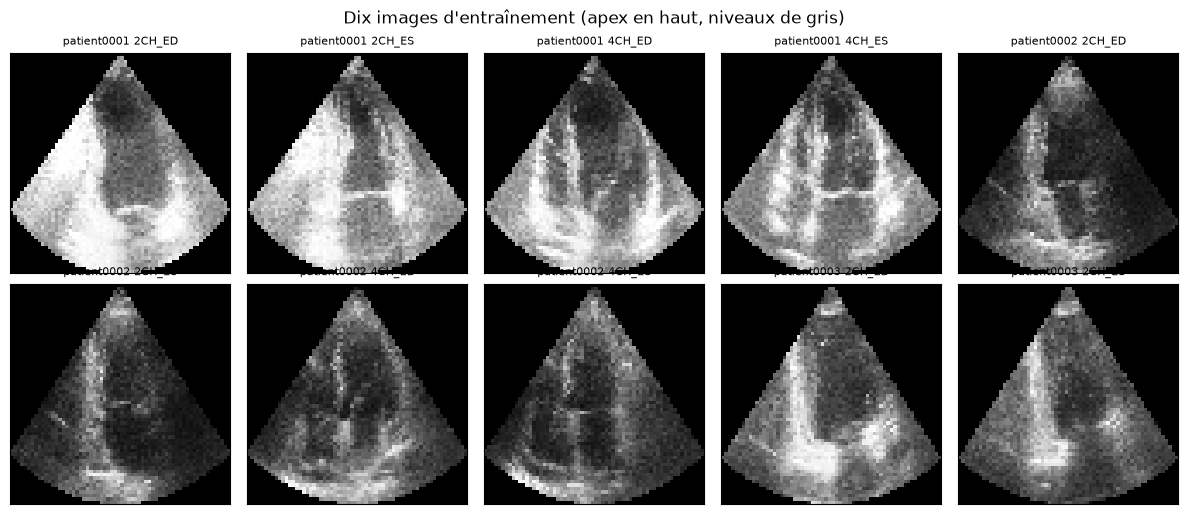

In [7]:
shapes = set()
mins, maxs = [], []
for subset in (train_dataset, valid_dataset, test_dataset):
    for record in subset.records:
        image = record["image"]
        shapes.add(tuple(image.shape))
        mins.append(float(image.min()))
        maxs.append(float(image.max()))
        stored = record["lv_area"]
        computed = float((record["label"].numpy() == 1).mean())
        assert abs(stored - computed) < 1e-6

assert shapes == {(IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)}, shapes
assert min(mins) >= 0.0 and max(maxs) <= 1.0
print(f"Forme unique : {shapes.pop()}   canal d'entrée in_channels={IN_CHANNELS}")
print(f"Intensités sur les trois sous-ensembles : [{min(mins):.3f}, {max(maxs):.3f}]")

probe_batch = next(iter(train_loader))
area_batch = torch.as_tensor(probe_batch["lv_area"], dtype=torch.float32)
area_from_label = (probe_batch["label"] == 1).float().mean(dim=(1, 2))
assert torch.allclose(area_batch, area_from_label, atol=1e-5)
print(f"Collation de lv_area : tenseur {tuple(area_batch.shape)}, aligné sur le masque.")


def mean_lv_area(records, instant=None, view=None):
    values = [
        record["lv_area"]
        for record in records
        if (instant is None or record["instant"] == instant)
        and (view is None or record["view"] == view)
    ]
    return float(np.mean(values))


for name, subset in (
    ("entraînement", train_dataset),
    ("validation", valid_dataset),
    ("test", test_dataset),
):
    counts = Counter(record["view_instant"] for record in subset.records)
    print(
        f"{name:14s} {dict(sorted(counts.items()))}  "
        f"lv_area ED {mean_lv_area(subset.records, 'ED'):.4f}  "
        f"ES {mean_lv_area(subset.records, 'ES'):.4f}"
    )

assert mean_lv_area(train_dataset.records, "ED") > mean_lv_area(train_dataset.records, "ES")
heart_fraction = float(np.mean([
    (record["label"] > 0).float().mean().item()
    for record in train_dataset.records
]))
print(f"Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : {heart_fraction:.3f}")
print(f"Aire moyenne de la cavité VG sur l'entraînement : {mean_lv_area(train_dataset.records):.3f}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, index in zip(axes.ravel(), range(10)):
    record = train_dataset[index]
    ax.imshow(record["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{record['patient']} {record['view_instant']}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Dix images d'entraînement (apex en haut, niveaux de gris)")
fig.tight_layout()
plt.show()


## 2. Architecture (`AutoencoderKL`)

Le modèle est un `AutoencoderKL` 2D. L'encodeur produit les paramètres d'une gaussienne diagonale. Un échantillon de cette gaussienne est décodé en une image.

`channels=(16, 32, 64, 64)` donne trois sous-échantillonnages : 64 → 32 → 16 → 8. Avec `latent_channels=8`, le code est un tenseur 8×8×8, soit 512 coefficients pour 4096 pixels (compression ×8). L'expérience 1 utilisait les mêmes canaux avec un code 4×8×8. L'expérience 2 élargissait le réseau jusqu'à 128 canaux pour le même code 8×8×8, et passait à 1,89 million de paramètres. Ici la largeur reste celle de l'expérience 1 : le surcoût se limite aux convolutions du goulot, et le temps CPU doit rester du même ordre.

L'attention spatiale et les blocs non locaux sont désactivés, et chaque niveau n'a qu'un bloc résiduel. `norm_num_groups=16` divise tous les nombres de canaux.


In [8]:
CHANNELS = (16, 32, 64, 64)
LATENT_CHANNELS = 8
ATTENTION_LEVELS = (False,) * len(CHANNELS)
NORM_GROUPS = 16
NUM_RES_BLOCKS = 1

assert all(channel % NORM_GROUPS == 0 for channel in CHANNELS)
assert len(ATTENTION_LEVELS) == len(CHANNELS)


def build_vae(seed=SEED):
    set_seed(seed)
    model = AutoencoderKL(
        spatial_dims=2,
        in_channels=IN_CHANNELS,
        out_channels=1,
        num_res_blocks=NUM_RES_BLOCKS,
        channels=CHANNELS,
        attention_levels=ATTENTION_LEVELS,
        latent_channels=LATENT_CHANNELS,
        norm_num_groups=NORM_GROUPS,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    )
    return model.to(device)


model = build_vae(SEED)
print(summary(
    model,
    input_size=(BATCH_SIZE, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
    depth=2,
    col_names=["input_size", "output_size", "num_params"],
    verbose=0,
    device="cpu",
))

with torch.no_grad():
    probe, mu, sigma = model(torch.zeros(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=device))

LATENT_SHAPE = tuple(mu.shape[1:])
downsamples = len(CHANNELS) - 1
expected_latent = (
    LATENT_CHANNELS,
    IMAGE_SIZE // 2**downsamples,
    IMAGE_SIZE // 2**downsamples,
)
assert LATENT_SHAPE == expected_latent, (LATENT_SHAPE, expected_latent)
assert tuple(sigma.shape[1:]) == LATENT_SHAPE
assert tuple(probe.shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

N_PARAMS = sum(parameter.numel() for parameter in model.parameters())
pixels = IN_CHANNELS * IMAGE_SIZE * IMAGE_SIZE
latent_size = int(np.prod(LATENT_SHAPE))
assert 470_000 <= N_PARAMS <= 490_000, N_PARAMS
print(f"Reconstruction {tuple(probe.shape)}, moyenne latente {LATENT_SHAPE}, sigma {tuple(sigma.shape)}")
print(f"Paramètres entraînables : {N_PARAMS:,}".replace(",", " "))
print(f"Code latent : {latent_size} coefficients pour {pixels} pixels, compression ×{pixels / latent_size:.0f}")
print("Convolutions du goulot :")
for name in ("quant_conv_mu", "quant_conv_log_sigma", "post_quant_conv"):
    layer = getattr(model, name)
    conv = layer.conv if hasattr(layer, "conv") else layer
    print(
        f"  {name}: noyau {tuple(conv.kernel_size)}, "
        f"pas {tuple(conv.stride)}, padding {tuple(conv.padding)}"
    )


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AutoencoderKL                            [64, 1, 64, 64]           [64, 1, 64, 64]           --
├─Encoder: 1-1                           [64, 1, 64, 64]           [64, 8, 8, 8]             --
│    └─ModuleList: 2-1                   --                        --                        204,472
├─Convolution: 1-2                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-2                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-3                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-3                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-4                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-4                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Decoder: 1-5                

### Lecture du goulot

Le résumé montre un encodeur qui se termine sur une grille spatiale 8×8, trois convolutions qui restent à cette taille, et un décodeur qui revient à une image 1×64×64.

Ces trois convolutions sont `quant_conv_mu`, `quant_conv_log_sigma` et `post_quant_conv`. Chacune a un noyau 1×1 : elles ne changent pas la taille spatiale. Les deux premières lisent les cartes de l'encodeur et produisent μ et log σ². L'implémentation MONAI borne la log-variance et renvoie σ = exp(log σ² / 2). `post_quant_conv` mélange le code échantillonné avant le décodeur.

Pendant l'entraînement, le décodeur reçoit z = μ + ε σ (astuce de reparamétrisation). À l'évaluation, on décode μ, la moyenne a posteriori, pour que la reconstruction soit déterministe. `AutoencoderKL.forward` échantillonne même en mode `eval`. L'entraînement et la validation appellent donc `encode`, `sampling` et `decode` explicitement.


## 3. Perte hybride et entraînement

La perte a quatre termes. La reconstruction mélange une L1 pondérée par l'anatomie et le SSIM. La KL rapproche le postérieur de la loi normale standard, avec un poids β qui monte pendant les premières époques. Le terme d'attribut ordonne une coordonnée de μ selon l'aire de la cavité.

$$L_{\text{total}} = L_{\text{recon}} + \beta(t) \cdot \text{KL} + \gamma \cdot L_{\text{attr}}$$

$$L_{\text{recon}} = 0.7 \cdot L_{1,\text{pondérée}}(x, \hat{x}, W) + 0.3 \cdot \text{SSIMLoss}\big(\text{clamp}(\hat{x}, 0, 1),\, x\big)$$

$$W = 1 + 2 \cdot \mathbb{I}(\text{label} > 0)$$

$$L_{1,\text{pondérée}} = \frac{\sum_p W_p \, |x_p - \hat{x}_p|}{\sum_p W_p}$$

Le poids vaut 3 sur la cavité VG, le myocarde et l'oreillette gauche, et 1 sur le fond. Le masque sert à construire W. Il n'est pas concaténé à l'image.

`SSIMLoss` de MONAI (spatial_dims=2, data_range=1, fenêtre 7) vaut 1 − SSIM. On le calcule sur la reconstruction bornée à [0, 1]. La L1, elle, voit la sortie brute : une valeur hors de [0, 1] reste pénalisée. La MSE brute est enregistrée à chaque époque pour la comparaison avec les expériences 1 et 2. Elle n'entre pas dans le gradient.

Pour une gaussienne diagonale, la KL est sommée sur les coefficients latents puis moyennée sur le lot :

$$\text{KL} = \frac{1}{2} \sum_i \big(\mu_i^2 + \sigma_i^2 - \log(\sigma_i^2) - 1\big)$$

La somme porte sur 8×8×8 = 512 coefficients. β part de 0 et atteint 1e-4 à l'époque 5 :

$$\beta(t) = 10^{-4} \cdot \min\left(1,\ \frac{t - 1}{4}\right)$$

pour l'époque t = 1, 2, …. Les époques 1 à 4 ne sont pas comparables entre elles sur la perte totale, puisque le poids de la KL change. Le checkpoint retient le minimum de la perte totale de validation à partir de l'époque 5, une fois β au plateau.

L'attribut est l'aire normalisée de la cavité, label 1 seulement (le poids W, lui, couvre tout le cœur) :

$$z_0 = \mathrm{mean}_{h,w}\big(\mu[:, 0]\big), \qquad a = \mathrm{mean}_{h,w}\big(\mathbb{I}(\text{label} = 1)\big)$$

$$L_{\text{attr}} = \mathrm{moyenne}_{i \neq j} \Big| \tanh\big(\delta (z_{0,i} - z_{0,j})\big) - \mathrm{sign}(a_i - a_j) \Big|$$

avec δ = 5 et γ = 1e-3. La moyenne est prise sur les paires du lot. z₀ est lu sur μ, en entraînement comme en validation : on régularise la moyenne a posteriori, pas l'échantillon bruité.

L'optimiseur est AdamW (lr = 1e-3, weight decay = 1e-5). Le pas suit un cosinus de 1e-3 jusqu'à 1e-5 sur les 20 époques. Les gradients sont tronqués à 1. L'entraînement décode z = μ + ε σ. La validation décode μ.


β max = 1e-04   γ = 1e-03   δ = 5.0   époques = 20   TRAIN = True
Calendrier de β :
  époque 01  β = 0.000e+00
  époque 02  β = 2.500e-05
  époque 03  β = 5.000e-05
  époque 04  β = 7.500e-05
  époque 05  β = 1.000e-04
  époque 06  β = 1.000e-04


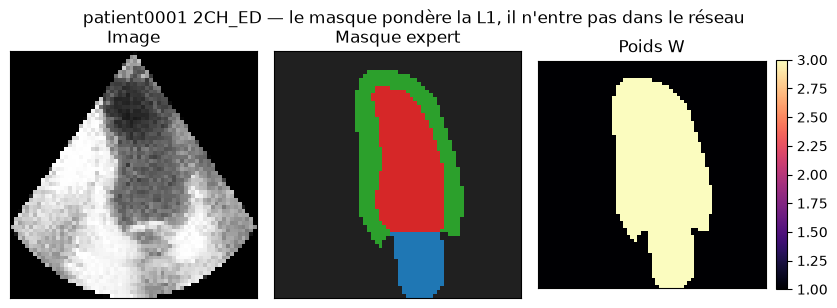

In [9]:
BETA_MAX = 1e-4
WARMUP_EPOCHS = 5
GAMMA = 1e-3
DELTA = 5.0
L1_WEIGHT = 0.7
SSIM_WEIGHT = 0.3
LR = 1e-3
WEIGHT_DECAY = 1e-5
ETA_MIN = 1e-5
N_EPOCHS = int(os.environ.get("CAMUS_EXP3_EPOCHS", "20"))
TRAIN = os.environ.get("CAMUS_EXP3_TRAIN", "1") not in {"0", "false", "False"}

ssim_loss = SSIMLoss(spatial_dims=2, data_range=1.0, win_size=7).to(device)
ssim_metric = SSIMMetric(spatial_dims=2, data_range=1.0, win_size=7, reduction="none")


def beta_at(epoch):
    # epoch commence à 1. Époque 1 : 0. Époque 5 et suivantes : BETA_MAX.
    progress = (epoch - 1) / (WARMUP_EPOCHS - 1)
    return BETA_MAX * min(1.0, max(0.0, progress))


def kl_divergence(mu, sigma):
    sigma = sigma.clamp_min(1e-6)
    kl = 0.5 * torch.sum(
        mu.pow(2) + sigma.pow(2) - torch.log(sigma.pow(2)) - 1,
        dim=tuple(range(1, mu.ndim)),
    )
    return kl.mean()


def attribute_loss(mu, label):
    z0 = mu[:, 0].mean(dim=(1, 2))
    area = (label == 1).to(dtype=z0.dtype).mean(dim=(1, 2))
    if z0.shape[0] < 2:
        return z0.new_zeros(())
    diff_z = z0[:, None] - z0[None, :]
    diff_a = area[:, None] - area[None, :]
    eye = torch.eye(z0.shape[0], dtype=torch.bool, device=z0.device)
    residual = torch.tanh(DELTA * diff_z) - torch.sign(diff_a)
    return residual.abs()[~eye].mean()


def batch_losses(recon, image, label, mu, sigma, beta):
    weights = 1.0 + 2.0 * (label > 0).to(dtype=recon.dtype).unsqueeze(1)
    l1 = (weights * (recon - image).abs()).sum() / weights.sum().clamp_min(1.0)
    ssim_term = ssim_loss(recon.clamp(0, 1), image)
    recon_loss = L1_WEIGHT * l1 + SSIM_WEIGHT * ssim_term
    kl_loss = kl_divergence(mu, sigma)
    attr = attribute_loss(mu, label)
    total = recon_loss + beta * kl_loss + GAMMA * attr
    mse = (recon - image).pow(2).mean().detach()
    return total, recon_loss.detach(), mse, kl_loss.detach(), attr.detach()


print(f"β max = {BETA_MAX:.0e}   γ = {GAMMA:.0e}   δ = {DELTA:.1f}   époques = {N_EPOCHS}   TRAIN = {TRAIN}")
print("Calendrier de β :")
for epoch in range(1, WARMUP_EPOCHS + 2):
    print(f"  époque {epoch:02d}  β = {beta_at(epoch):.3e}")

example = train_dataset[0]
label_np = example["label"].numpy()
weight_np = 1.0 + 2.0 * (label_np > 0).astype(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.1))
axes[0].imshow(example["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(label_np, cmap=HEART_CMAP, vmin=0, vmax=3, interpolation="nearest")
weight_image = axes[2].imshow(weight_np, cmap="magma", vmin=1, vmax=3)
axes[0].set_title("Image")
axes[1].set_title("Masque expert")
axes[2].set_title("Poids W")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(weight_image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle(f"{example['patient']} {example['view_instant']} — le masque pondère la L1, il n'entre pas dans le réseau")
fig.tight_layout()
plt.show()


In [10]:
CONFIG = {
    "spatial_dims": 2,
    "in_channels": IN_CHANNELS,
    "out_channels": 1,
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "latent_channels": LATENT_CHANNELS,
    "latent_shape": list(LATENT_SHAPE),
    "norm_num_groups": NORM_GROUPS,
    "num_res_blocks": NUM_RES_BLOCKS,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_l1_weight": L1_WEIGHT,
    "recon_ssim_weight": SSIM_WEIGHT,
    "heart_weight": 2.0,
    "recon_loss": "0.7*weighted_l1+0.3*ssim",
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "epochs": N_EPOCHS,
}


def train_vae(model, n_epochs, config, lr=LR):
    set_seed(SEED)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(n_epochs, 1), eta_min=ETA_MIN,
    )
    history = {
        key: []
        for key in (
            "train_total", "train_recon", "train_mse", "train_kl", "train_attr",
            "val_total", "val_recon", "val_mse", "val_kl", "val_attr", "val_ssim",
            "beta", "lr",
        )
    }
    history.update({
        "beta_max": BETA_MAX,
        "gamma": GAMMA,
        "delta": DELTA,
        "epochs": n_epochs,
        "warmup_epochs": WARMUP_EPOCHS,
        "recon": "0.7*weighted_l1+0.3*ssim",
    })
    best_score = float("inf")
    best_state = None
    best_epoch = 0
    first_selectable = min(WARMUP_EPOCHS, n_epochs)
    clock = time.perf_counter()
    log_path = ARTIFACT_DIR / "exp3_train.log"
    log_file = log_path.open("w", encoding="utf-8")
    print(f"Checkpoint à partir de l'époque {first_selectable}. Journal : {log_path}")

    for epoch in range(n_epochs):
        beta = beta_at(epoch + 1)
        lr_now = float(optimizer.param_groups[0]["lr"])
        model.train()
        totals = {key: 0.0 for key in ("total", "recon", "mse", "kl", "attr")}
        seen = 0
        for batch in train_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)
            optimizer.zero_grad(set_to_none=True)
            mu, sigma = model.encode(images)
            z = model.sampling(mu, sigma)
            recon = model.decode(z)
            total, recon_loss, mse, kl_loss, attr = batch_losses(
                recon, images, labels, mu, sigma, beta,
            )
            if not torch.isfinite(total):
                raise RuntimeError(f"Perte d'entraînement non finie à l'époque {epoch + 1}")
            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_size = images.size(0)
            totals["total"] += float(total.detach()) * batch_size
            totals["recon"] += float(recon_loss) * batch_size
            totals["mse"] += float(mse) * batch_size
            totals["kl"] += float(kl_loss) * batch_size
            totals["attr"] += float(attr) * batch_size
            seen += batch_size
        train_means = {key: value / seen for key, value in totals.items()}

        model.eval()
        totals = {key: 0.0 for key in ("total", "recon", "mse", "kl", "attr", "ssim")}
        seen = 0
        with torch.no_grad():
            for batch in valid_loader:
                images = batch["image"].to(device)
                labels = batch["label"].to(device)
                mu, sigma = model.encode(images)
                recon = model.decode(mu)
                total, recon_loss, mse, kl_loss, attr = batch_losses(
                    recon, images, labels, mu, sigma, beta,
                )
                if not torch.isfinite(total):
                    raise RuntimeError(f"Perte de validation non finie à l'époque {epoch + 1}")
                ssim_values = ssim_metric(recon.clamp(0, 1), images.clamp(0, 1)).reshape(-1)
                batch_size = images.size(0)
                if ssim_values.numel() != batch_size:
                    raise RuntimeError(
                        f"SSIM de forme {tuple(ssim_values.shape)} pour un lot de {batch_size}"
                    )
                totals["total"] += float(total) * batch_size
                totals["recon"] += float(recon_loss) * batch_size
                totals["mse"] += float(mse) * batch_size
                totals["kl"] += float(kl_loss) * batch_size
                totals["attr"] += float(attr) * batch_size
                totals["ssim"] += float(ssim_values.sum())
                seen += batch_size
        val_means = {key: value / seen for key, value in totals.items()}

        history["train_total"].append(train_means["total"])
        history["train_recon"].append(train_means["recon"])
        history["train_mse"].append(train_means["mse"])
        history["train_kl"].append(train_means["kl"])
        history["train_attr"].append(train_means["attr"])
        history["val_total"].append(val_means["total"])
        history["val_recon"].append(val_means["recon"])
        history["val_mse"].append(val_means["mse"])
        history["val_kl"].append(val_means["kl"])
        history["val_attr"].append(val_means["attr"])
        history["val_ssim"].append(val_means["ssim"])
        history["beta"].append(beta)
        history["lr"].append(lr_now)

        saved = False
        if (epoch + 1) >= first_selectable and val_means["total"] < best_score:
            best_score = val_means["total"]
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            history["best_epoch"] = best_epoch
            history["best_val"] = best_score
            torch.save(
                {
                    "state_dict": best_state,
                    "epoch": best_epoch,
                    "history": history,
                    "config": config,
                },
                CHECKPOINT_PATH,
            )
            saved = True

        flag = "  checkpoint" if saved else ""
        line = (
            f"Époque {epoch + 1:02d}/{n_epochs}  "
            f"β={beta:.2e}  lr={lr_now:.2e}  "
            f"train {train_means['total']:.5f} "
            f"(recon {train_means['recon']:.5f}, mse {train_means['mse']:.5f}, "
            f"kl {train_means['kl']:.2f}, attr {train_means['attr']:.4f})  "
            f"val {val_means['total']:.5f} "
            f"(recon {val_means['recon']:.5f}, mse {val_means['mse']:.5f}, "
            f"kl {val_means['kl']:.2f}, attr {val_means['attr']:.4f}, "
            f"ssim {val_means['ssim']:.3f})"
            f"{flag}"
        )
        print(line, flush=True)
        log_file.write(line + "\n")
        log_file.flush()
        scheduler.step()

    history["seconds"] = time.perf_counter() - clock
    history["best_epoch"] = best_epoch
    history["best_val"] = best_score
    if best_state is None:
        raise RuntimeError("Aucun checkpoint : la sélection n'a retenu aucune époque.")
    model.load_state_dict(best_state)
    torch.save(
        {
            "state_dict": model.state_dict(),
            "epoch": best_epoch,
            "history": history,
            "config": config,
        },
        CHECKPOINT_PATH,
    )
    log_file.write(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"perte de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.1f} min.\n"
    )
    log_file.close()
    print(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"perte de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.1f} min."
    )
    print(f"Poids enregistrés dans {CHECKPOINT_PATH}.")
    return model, history


model = build_vae(SEED)
if TRAIN:
    model, history = train_vae(model, N_EPOCHS, CONFIG, lr=LR)
else:
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
    payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(payload["state_dict"])
    history = payload["history"]
    print(f"Poids rechargés : {CHECKPOINT_PATH} (époque {history['best_epoch']})")


Checkpoint à partir de l'époque 5. Journal : artifacts/exp3_train.log


Époque 01/20  β=0.00e+00  lr=1.00e-03  train 0.35678 (recon 0.35580, mse 0.09831, kl 310.66, attr 0.9803)  val 0.28234 (recon 0.28134, mse 0.05052, kl 520.15, attr 0.9924, ssim 0.440)


Époque 02/20  β=2.50e-05  lr=9.94e-04  train 0.26208 (recon 0.25407, mse 0.03391, kl 280.98, attr 0.9844)  val 0.20671 (recon 0.19824, mse 0.01731, kl 299.06, attr 0.9935, ssim 0.571)


Époque 03/20  β=5.00e-05  lr=9.76e-04  train 0.22166 (recon 0.20765, mse 0.01849, kl 260.00, attr 1.0110)  val 0.19158 (recon 0.17964, mse 0.01387, kl 218.54, attr 1.0051, ssim 0.609)


Époque 04/20  β=7.50e-05  lr=9.46e-04  train 0.20174 (recon 0.18627, mse 0.01494, kl 192.83, attr 1.0115)  val 0.17476 (recon 0.15999, mse 0.01062, kl 183.53, attr 1.0029, ssim 0.638)


Époque 05/20  β=1.00e-04  lr=9.05e-04  train 0.20014 (recon 0.18304, mse 0.01420, kl 160.95, attr 1.0093)  val 0.17365 (recon 0.15736, mse 0.01035, kl 152.80, attr 1.0026, ssim 0.644)  checkpoint


... (12 outputs left out)

Époque 18/20  β=1.00e-04  lr=6.40e-05  train 0.15557 (recon 0.13999, mse 0.01010, kl 145.84, attr 0.9989)  val 0.14463 (recon 0.12905, mse 0.00842, kl 145.83, attr 0.9963, ssim 0.716)  checkpoint


Époque 19/20  β=1.00e-04  lr=3.42e-05  train 0.15524 (recon 0.13965, mse 0.01006, kl 145.90, attr 0.9991)  val 0.14435 (recon 0.12877, mse 0.00835, kl 145.82, attr 0.9965, ssim 0.717)  checkpoint


Époque 20/20  β=1.00e-04  lr=1.61e-05  train 0.15475 (recon 0.13913, mse 0.01002, kl 146.18, attr 0.9997)  val 0.14408 (recon 0.12847, mse 0.00836, kl 146.08, attr 0.9965, ssim 0.717)  checkpoint


Meilleure époque 20/20, perte de validation 0.144076, durée 12.6 min.
Poids enregistrés dans checkpoints/exp3_vae_best.pth.


### Courbes

La reconstruction d'entraînement décode un échantillon z. Celle de validation décode μ. La courbe de validation peut donc se placer un peu sous la courbe d'entraînement sans que cela indique un sur-apprentissage. Un sur-apprentissage se lirait comme une validation qui remonte pendant que l'entraînement continue de descendre.

Pendant les quatre premières époques, β augmente et la perte totale change d'échelle. La MSE brute et le SSIM de validation, qui ne dépendent pas de β, portent le jugement sur la fidélité. La KL doit se stabiliser à une valeur finie et non nulle. La perte d'attribut doit descendre si l'ordre des aires de cavité s'inscrit dans z₀.


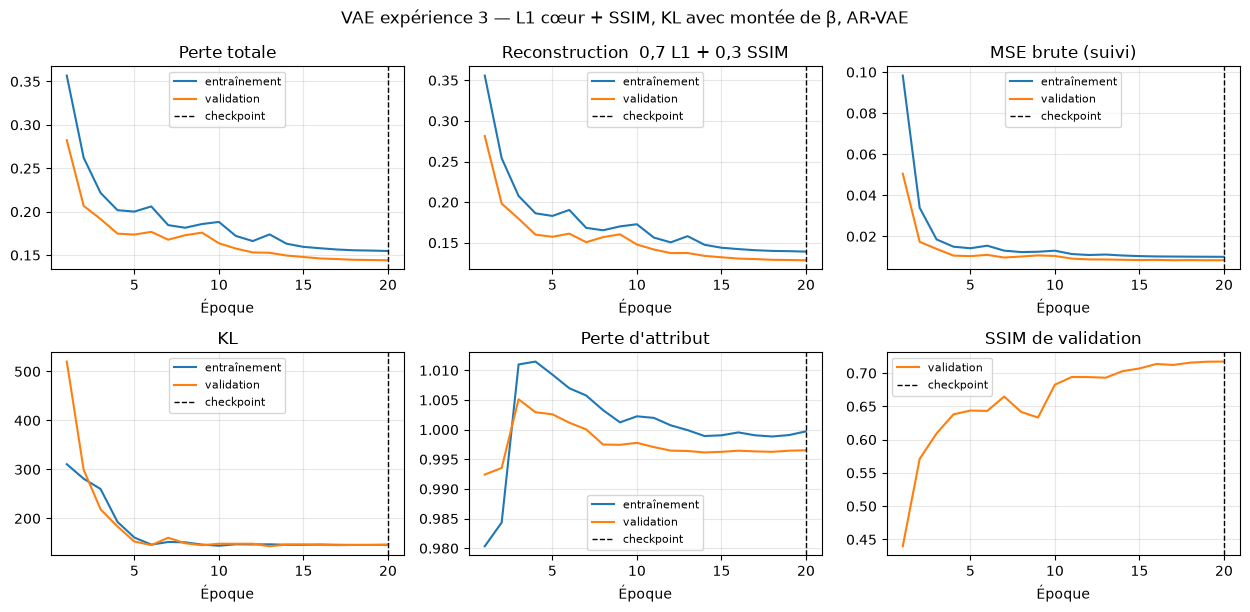

In [11]:
def plot_history(history):
    epochs = np.arange(1, len(history["train_total"]) + 1)
    fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.2))
    series = (
        ("total", "Perte totale"),
        ("recon", "Reconstruction  0,7 L1 + 0,3 SSIM"),
        ("mse", "MSE brute (suivi)"),
        ("kl", "KL"),
        ("attr", "Perte d'attribut"),
    )
    for ax, (key, title) in zip(axes.ravel(), series):
        ax.plot(epochs, history[f"train_{key}"], label="entraînement")
        ax.plot(epochs, history[f"val_{key}"], label="validation")
        ax.axvline(history["best_epoch"], color="black", ls="--", lw=1, label="checkpoint")
        ax.set_title(title)
        ax.set_xlabel("Époque")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    ax = axes.ravel()[5]
    ax.plot(epochs, history["val_ssim"], color="C1", label="validation")
    ax.axvline(history["best_epoch"], color="black", ls="--", lw=1, label="checkpoint")
    ax.set_title("SSIM de validation")
    ax.set_xlabel("Époque")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    fig.suptitle("VAE expérience 3 — L1 cœur + SSIM, KL avec montée de β, AR-VAE")
    fig.tight_layout()
    plt.show()


plot_history(history)


## 4. Évaluation

Le fichier `checkpoints/exp3_vae_best.pth` est rechargé avant le calcul des métriques. On décode μ sur les 200 images de `test_loader`.

La MSE, le MAE et le PSNR utilisent la sortie brute du décodeur : une valeur hors de [0, 1] est pénalisée. Le PSNR est celui de MONAI `PSNRMetric` avec un pic de 1. Le SSIM est celui de MONAI `SSIMMetric`, fenêtre de 7, après bornage à [0, 1], comme dans les expériences 1 et 2.

Le masque expert sépare l'erreur quadratique sur le cœur (labels 1, 2 et 3) et sur le fond. Cette séparation est une mesure, pas un terme de la perte de test. Le fond est en grande partie noir, donc une MSE globale basse peut coexister avec une cavité floue.


Poids rechargés : époque 20, perte de validation 0.144076, durée 12.6 min.


MSE moyenne sur les 200 images de test : 0.01024 ± 0.01042
MAE test :  0.061 ± 0.026
PSNR test : 20.84 ± 2.48 dB
SSIM test : 0.703 ± 0.052
MSE sur le cœur : 0.01298 ± 0.01028
MSE sur le fond : 0.00938 ± 0.01090


### MSE, PSNR et SSIM de test par vue et par instant

| Vue / instant | n | MSE | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- |
| 2CH_ED | 50 | 0.00996 | 21.15 | 0.702 |
| 2CH_ES | 50 | 0.01011 | 21.11 | 0.697 |
| 4CH_ED | 50 | 0.01056 | 20.50 | 0.707 |
| 4CH_ES | 50 | 0.01035 | 20.61 | 0.706 |

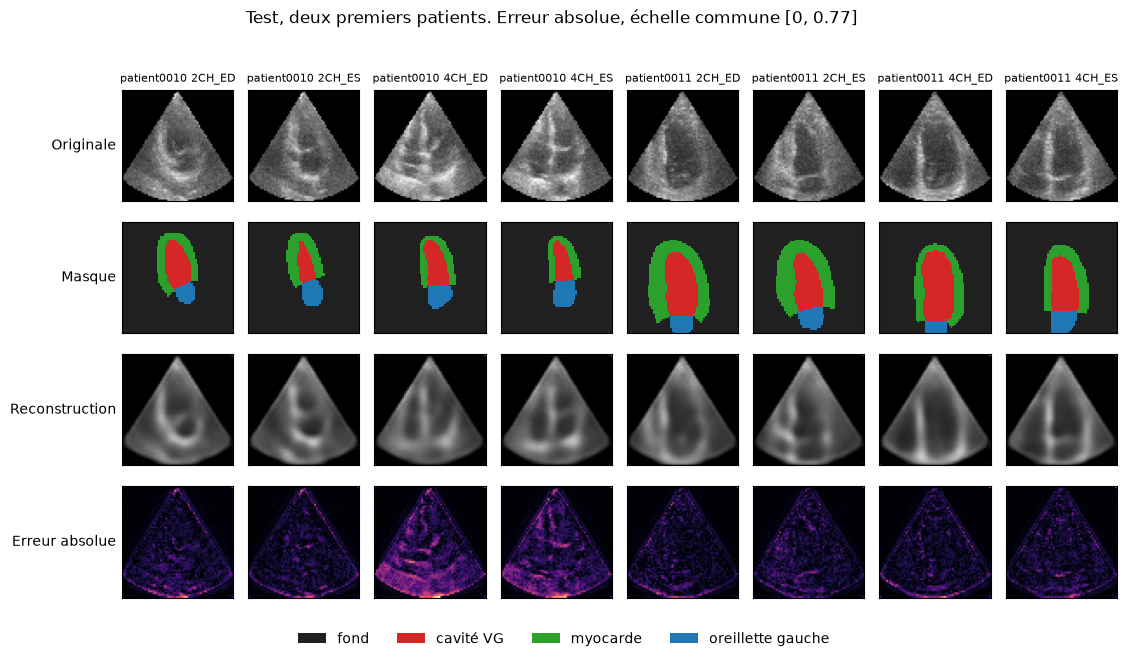

In [12]:
def make_ssim():
    return SSIMMetric(spatial_dims=2, data_range=1.0, win_size=7, reduction="none")


def reconstruction_scores(recon, target):
    error = recon - target
    mae = error.abs().mean(dim=(1, 2, 3)).detach().cpu().numpy()
    mse = error.pow(2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
    psnr = PSNRMetric(max_val=1.0, reduction="none")(recon, target).detach().cpu().numpy().reshape(-1)
    ssim = make_ssim()(recon.clamp(0, 1), target.clamp(0, 1)).detach().cpu().numpy().reshape(-1)
    return mae, mse, psnr, ssim


def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.mean(values)), float(np.std(values))


def fmt_mean_std(values, digits=3):
    mu, sigma = mean_std(values)
    return f"{mu:.{digits}f} ± {sigma:.{digits}f}"


def fmt_pm(mean, std, digits):
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


def fmt_int(value):
    return f"{int(value):,}".replace(",", " ")


def masked_mse(recon, image, label, inside):
    error = (recon - image).pow(2)
    mask = (label.unsqueeze(1) > 0) if inside else (label.unsqueeze(1) == 0)
    mask = mask.to(error.dtype)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1)
    return ((error * mask).sum(dim=(1, 2, 3)) / denom).detach().cpu().numpy()


def as_float_vector(value):
    if torch.is_tensor(value):
        return value.detach().cpu().float().reshape(-1)
    return torch.tensor(value, dtype=torch.float32).reshape(-1)


@torch.no_grad()
def collect_predictions(net, loader):
    net.eval()
    images, recons, labels, mus, areas = [], [], [], [], []
    view_instants, views, instants, patients = [], [], [], []
    for batch in loader:
        x = batch["image"].to(device)
        mu, sigma = net.encode(x)
        recon = net.decode(mu)
        images.append(batch["image"])
        recons.append(recon.cpu())
        labels.append(batch["label"])
        mus.append(mu.cpu())
        areas.append(as_float_vector(batch["lv_area"]))
        view_instants.extend(list(batch["view_instant"]))
        views.extend(list(batch["view"]))
        instants.extend(list(batch["instant"]))
        patients.extend(list(batch["patient"]))
    packed = {
        "image": torch.cat(images),
        "recon": torch.cat(recons),
        "label": torch.cat(labels),
        "mu": torch.cat(mus),
        "lv_area": torch.cat(areas).numpy(),
        "view_instant": np.asarray(view_instants),
        "view": np.asarray(views),
        "instant": np.asarray(instants),
        "patient": np.asarray(patients),
    }
    mae, mse, psnr, ssim = reconstruction_scores(packed["recon"], packed["image"])
    packed.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})
    return packed


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(cell) for cell in row) + " |")
    return "\n".join(lines)


if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
saved_config = payload["config"]
assert tuple(saved_config["channels"]) == tuple(CHANNELS)
assert saved_config["latent_channels"] == LATENT_CHANNELS
model.load_state_dict(payload["state_dict"])
history = payload["history"]
model.eval()
print(
    f"Poids rechargés : époque {payload['epoch']}, "
    f"perte de validation {history['best_val']:.6f}, "
    f"durée {history['seconds'] / 60:.1f} min."
)

test_pred = collect_predictions(model, test_loader)
assert len(test_pred["mse"]) == len(test_dataset) == 200
heart_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=True)
background_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=False)

print(f"MSE moyenne sur les {len(test_dataset)} images de test : {fmt_mean_std(test_pred['mse'], digits=5)}")
print(f"MAE test :  {fmt_mean_std(test_pred['mae'])}")
print(f"PSNR test : {fmt_mean_std(test_pred['psnr'], digits=2)} dB")
print(f"SSIM test : {fmt_mean_std(test_pred['ssim'])}")
print(f"MSE sur le cœur : {fmt_mean_std(heart_mse, digits=5)}")
print(f"MSE sur le fond : {fmt_mean_std(background_mse, digits=5)}")

per_class_rows = []
per_view_instant = {}
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    mse_mean, mse_std = mean_std(test_pred["mse"][selected])
    psnr_mean, psnr_std = mean_std(test_pred["psnr"][selected])
    ssim_mean, ssim_std = mean_std(test_pred["ssim"][selected])
    per_class_rows.append([
        view_instant,
        int(selected.sum()),
        f"{mse_mean:.5f}",
        f"{psnr_mean:.2f}",
        f"{ssim_mean:.3f}",
    ])
    per_view_instant[view_instant] = {
        "n": int(selected.sum()),
        "mse_mean": mse_mean,
        "mse_std": mse_std,
        "psnr_mean": psnr_mean,
        "psnr_std": psnr_std,
        "ssim_mean": ssim_mean,
        "ssim_std": ssim_std,
    }

display(Markdown(
    "### MSE, PSNR et SSIM de test par vue et par instant\n\n"
    + markdown_table(["Vue / instant", "n", "MSE", "PSNR (dB)", "SSIM"], per_class_rows)
))

n_show = 8
shown_error = (test_pred["recon"][:n_show] - test_pred["image"][:n_show]).abs()
error_vmax = float(shown_error.max().clamp_min(1e-3))
fig, axes = plt.subplots(4, n_show, figsize=(1.45 * n_show, 6.6))
row_names = ("Originale", "Masque", "Reconstruction", "Erreur absolue")
for index in range(n_show):
    axes[0, index].imshow(test_pred["image"][index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, index].imshow(
        test_pred["label"][index].numpy(),
        cmap=HEART_CMAP,
        vmin=0,
        vmax=3,
        interpolation="nearest",
    )
    axes[2, index].imshow(test_pred["recon"][index, 0].clamp(0, 1).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[3, index].imshow(shown_error[index, 0].numpy(), cmap="magma", vmin=0, vmax=error_vmax)
    axes[0, index].set_title(
        f"{test_pred['patient'][index]} {test_pred['view_instant'][index]}",
        fontsize=8,
    )
    for row in range(4):
        axes[row, index].set_xticks([])
        axes[row, index].set_yticks([])
for row, name in enumerate(row_names):
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
legend = [
    Patch(facecolor=HEART_CMAP(index / 3), edgecolor="none", label=LABEL_NAMES[index])
    for index in range(4)
]
fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False)
fig.suptitle(
    f"Test, deux premiers patients. Erreur absolue, échelle commune [0, {error_vmax:.2f}]"
)
fig.tight_layout(rect=(0.02, 0.05, 1, 0.96))
plt.show()


### Comparaison des trois expériences

Les métriques de test de l'expérience 1 sont lues dans `artifacts/results.json` (ligne du VAE retenu, β = 1e-4). Celles de l'expérience 2 sont lues dans `artifacts/results_exp2.json`. Les deux fichiers utilisent les mêmes définitions du PSNR et du SSIM que ce notebook.

`results.json` ne contient pas la MSE sur le cœur ni sur le fond. Ces deux quantités sont recalculées en rechargeant `checkpoints/vae_final.pth` (canaux de l'expérience 1, latent 4×8×8) et en le passant sur le même `test_loader`. La durée de l'expérience 1 est celle enregistrée dans ce checkpoint : 25 époques, pas les 20 époques des expériences 2 et 3. La durée par époque rend les trois runs comparables.

Cette comparaison mêle plusieurs changements : largeur du réseau, taille du latent, forme de la reconstruction, usage du masque dans la perte, montée de β, régularisation d'attribut, optimiseur. Un écart ne s'attribue pas à un seul facteur. Le tableau dit si l'ensemble des choix de l'expérience 3 améliore les points faibles mesurés dans les deux runs précédents.


In [13]:
def parse_pm(text):
    parts = str(text).split("±")
    mean = float(parts[0].strip().replace(",", "."))
    std = float(parts[1].strip()) if len(parts) > 1 else None
    return mean, std


def count_parameters(net):
    return sum(parameter.numel() for parameter in net.parameters())


def build_exp1_vae():
    net = AutoencoderKL(
        spatial_dims=2,
        in_channels=1,
        out_channels=1,
        num_res_blocks=1,
        channels=(16, 32, 64, 64),
        attention_levels=(False, False, False, False),
        latent_channels=4,
        norm_num_groups=16,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    )
    return net.to(device)


def load_json(path):
    if not path.is_file():
        print(f"{path} est absent.")
        return None
    return json.loads(path.read_text())


exp1_path = ARTIFACT_DIR / "results.json"
exp2_path = ARTIFACT_DIR / "results_exp2.json"
exp1_report = load_json(exp1_path)
exp2_report = load_json(exp2_path)

exp1_test = None
if exp1_report is not None and "test" in exp1_report:
    exp1_test = next(row for row in exp1_report["test"] if str(row["name"]).startswith("VAE"))
elif exp2_report is not None and "experiment_1" in exp2_report:
    exp1_test = exp2_report["experiment_1"].get("test_row")

exp1_ckpt_path = CHECKPOINT_DIR / "vae_final.pth"
exp1_seconds = None
exp1_epochs = None
exp1_best_epoch = None
exp1_heart_mean = exp1_heart_std = None
exp1_background_mean = exp1_background_std = None
exp1_params = None
exp1_recomputed_mse = None

if exp1_ckpt_path.is_file():
    exp1_model = build_exp1_vae()
    exp1_payload = torch.load(exp1_ckpt_path, map_location=device, weights_only=False)
    exp1_model.load_state_dict(exp1_payload["state_dict"])
    exp1_params = count_parameters(exp1_model)
    exp1_history = exp1_payload.get("history", {})
    exp1_seconds = float(exp1_history["seconds"]) if "seconds" in exp1_history else None
    exp1_epochs = int(exp1_history["epochs"]) if "epochs" in exp1_history else None
    exp1_best_epoch = int(exp1_history["best_epoch"]) if "best_epoch" in exp1_history else None
    exp1_pred = collect_predictions(exp1_model, test_loader)
    exp1_heart = masked_mse(exp1_pred["recon"], exp1_pred["image"], exp1_pred["label"], inside=True)
    exp1_background = masked_mse(exp1_pred["recon"], exp1_pred["image"], exp1_pred["label"], inside=False)
    exp1_heart_mean, exp1_heart_std = mean_std(exp1_heart)
    exp1_background_mean, exp1_background_std = mean_std(exp1_background)
    exp1_recomputed_mse, _ = mean_std(exp1_pred["mse"])
    print(
        f"Contrôle expérience 1 : MSE recalculée {exp1_recomputed_mse:.5f}"
        + (f", results.json {exp1_test['mse']}" if exp1_test else "")
    )
    del exp1_model, exp1_pred
else:
    print(f"{exp1_ckpt_path} est absent. MSE cœur / fond et durée de l'expérience 1 non recalculées.")
    if exp2_report and "experiment_1" in exp2_report:
        exp1_params = exp2_report["experiment_1"].get("n_params")

exp3_mse_mean, exp3_mse_std = mean_std(test_pred["mse"])
exp3_mae_mean, exp3_mae_std = mean_std(test_pred["mae"])
exp3_psnr_mean, exp3_psnr_std = mean_std(test_pred["psnr"])
exp3_ssim_mean, exp3_ssim_std = mean_std(test_pred["ssim"])
exp3_heart_mean, exp3_heart_std = mean_std(heart_mse)
exp3_background_mean, exp3_background_std = mean_std(background_mse)


def blank_column(name):
    return {
        "name": name,
        "latent": None,
        "n_params": None,
        "epochs": None,
        "best_epoch": None,
        "seconds": None,
        "seconds_per_epoch": None,
        "mse": None,
        "mse_std": None,
        "mse_display": "n.d.",
        "mae": None,
        "mae_display": "n.d.",
        "psnr": None,
        "psnr_display": "n.d.",
        "ssim": None,
        "ssim_display": "n.d.",
        "heart_mse": None,
        "heart_mse_display": "n.d.",
        "background_mse": None,
        "background_mse_display": "n.d.",
    }


column_exp1 = blank_column("Expérience 1")
column_exp1["latent"] = "4×8×8"
if exp1_report and "latent_shape" in exp1_report:
    column_exp1["latent"] = "×".join(str(value) for value in exp1_report["latent_shape"])
column_exp1["n_params"] = exp1_params
column_exp1["epochs"] = exp1_epochs
column_exp1["best_epoch"] = exp1_best_epoch
column_exp1["seconds"] = exp1_seconds
if exp1_seconds is not None and exp1_epochs:
    column_exp1["seconds_per_epoch"] = exp1_seconds / exp1_epochs
if exp1_test is not None:
    column_exp1["mse"], column_exp1["mse_std"] = parse_pm(exp1_test["mse"])
    column_exp1["mae"], _ = parse_pm(exp1_test["mae"])
    column_exp1["psnr"], _ = parse_pm(exp1_test["psnr"])
    column_exp1["ssim"], _ = parse_pm(exp1_test["ssim"])
    column_exp1["mse_display"] = exp1_test["mse"]
    column_exp1["mae_display"] = exp1_test["mae"]
    column_exp1["psnr_display"] = exp1_test["psnr"]
    column_exp1["ssim_display"] = exp1_test["ssim"]
column_exp1["heart_mse"] = exp1_heart_mean
column_exp1["background_mse"] = exp1_background_mean
if exp1_heart_mean is not None:
    column_exp1["heart_mse_display"] = fmt_pm(exp1_heart_mean, exp1_heart_std, 5)
    column_exp1["background_mse_display"] = fmt_pm(exp1_background_mean, exp1_background_std, 5)
column_exp1["metrics_source"] = str(exp1_path) if exp1_test is not None else None
column_exp1["heart_mse_source"] = "checkpoints/vae_final.pth" if exp1_heart_mean is not None else None

column_exp2 = blank_column("Expérience 2")
if exp2_report is not None:
    column_exp2["latent"] = "×".join(str(value) for value in exp2_report["latent_shape"])
    column_exp2["n_params"] = exp2_report["n_params"]
    column_exp2["epochs"] = exp2_report["epochs"]
    column_exp2["best_epoch"] = exp2_report["best_epoch"]
    column_exp2["seconds"] = exp2_report["seconds"]
    column_exp2["seconds_per_epoch"] = exp2_report["seconds"] / exp2_report["epochs"]
    test2 = exp2_report["test"]
    column_exp2["mse"] = test2["mse_mean"]
    column_exp2["mse_std"] = test2["mse_std"]
    column_exp2["mae"] = test2["mae_mean"]
    column_exp2["psnr"] = test2["psnr_mean"]
    column_exp2["ssim"] = test2["ssim_mean"]
    column_exp2["heart_mse"] = test2["heart_mse_mean"]
    column_exp2["background_mse"] = test2["background_mse_mean"]
    column_exp2["mse_display"] = fmt_pm(test2["mse_mean"], test2["mse_std"], 5)
    column_exp2["mae_display"] = fmt_pm(test2["mae_mean"], test2["mae_std"], 3)
    column_exp2["psnr_display"] = fmt_pm(test2["psnr_mean"], test2["psnr_std"], 2)
    column_exp2["ssim_display"] = fmt_pm(test2["ssim_mean"], test2["ssim_std"], 3)
    column_exp2["heart_mse_display"] = fmt_pm(test2["heart_mse_mean"], test2["heart_mse_std"], 5)
    column_exp2["background_mse_display"] = fmt_pm(
        test2["background_mse_mean"], test2["background_mse_std"], 5,
    )
    column_exp2["metrics_source"] = str(exp2_path)

column_exp3 = blank_column("Expérience 3")
column_exp3.update({
    "latent": "×".join(str(value) for value in LATENT_SHAPE),
    "n_params": N_PARAMS,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "seconds": history["seconds"],
    "seconds_per_epoch": history["seconds"] / history["epochs"],
    "mse": exp3_mse_mean,
    "mse_std": exp3_mse_std,
    "mae": exp3_mae_mean,
    "psnr": exp3_psnr_mean,
    "ssim": exp3_ssim_mean,
    "heart_mse": exp3_heart_mean,
    "background_mse": exp3_background_mean,
    "mse_display": fmt_pm(exp3_mse_mean, exp3_mse_std, 5),
    "mae_display": fmt_pm(exp3_mae_mean, exp3_mae_std, 3),
    "psnr_display": fmt_pm(exp3_psnr_mean, exp3_psnr_std, 2),
    "ssim_display": fmt_pm(exp3_ssim_mean, exp3_ssim_std, 3),
    "heart_mse_display": fmt_pm(exp3_heart_mean, exp3_heart_std, 5),
    "background_mse_display": fmt_pm(exp3_background_mean, exp3_background_std, 5),
    "metrics_source": "test_loader, checkpoints/exp3_vae_best.pth",
})
comparison_columns = {"1": column_exp1, "2": column_exp2, "3": column_exp3}


def minutes_display(column):
    if column["seconds"] is None:
        return "n.d."
    return f"{column['seconds'] / 60:.1f} min"


def per_epoch_display(column):
    if column["seconds_per_epoch"] is None:
        return "n.d."
    return f"{column['seconds_per_epoch']:.1f} s"


def epochs_display(column):
    if column["epochs"] is None:
        return "n.d."
    if column["best_epoch"] is None:
        return str(column["epochs"])
    return f"{column['epochs']} (meilleure {column['best_epoch']})"


def mark_best(displays, values, higher):
    valid = [value for value in values if value is not None]
    if not valid:
        return displays
    target = max(valid) if higher else min(valid)
    marked = []
    for display, value in zip(displays, values):
        if value is not None and abs(value - target) <= 1e-9 * max(1.0, abs(target)):
            marked.append(f"**{display}**")
        else:
            marked.append(display)
    return marked


columns = (column_exp1, column_exp2, column_exp3)
headers = ["", "Expérience 1", "Expérience 2", "Expérience 3"]
table_rows = [
    ["Code latent", *[column["latent"] or "n.d." for column in columns]],
    ["Paramètres", *[fmt_int(column["n_params"]) if column["n_params"] else "n.d." for column in columns]],
    ["Époques", *[epochs_display(column) for column in columns]],
    ["Durée totale", *mark_best(
        [minutes_display(column) for column in columns],
        [column["seconds"] for column in columns],
        higher=False,
    )],
    ["Durée par époque", *mark_best(
        [per_epoch_display(column) for column in columns],
        [column["seconds_per_epoch"] for column in columns],
        higher=False,
    )],
    ["MSE test", *mark_best(
        [column["mse_display"] for column in columns],
        [column["mse"] for column in columns],
        higher=False,
    )],
    ["MAE test", *mark_best(
        [column["mae_display"] for column in columns],
        [column["mae"] for column in columns],
        higher=False,
    )],
    ["PSNR test (dB)", *mark_best(
        [column["psnr_display"] for column in columns],
        [column["psnr"] for column in columns],
        higher=True,
    )],
    ["SSIM test", *mark_best(
        [column["ssim_display"] for column in columns],
        [column["ssim"] for column in columns],
        higher=True,
    )],
    ["MSE cœur", *mark_best(
        [column["heart_mse_display"] for column in columns],
        [column["heart_mse"] for column in columns],
        higher=False,
    )],
    ["MSE fond", *mark_best(
        [column["background_mse_display"] for column in columns],
        [column["background_mse"] for column in columns],
        higher=False,
    )],
]

display(Markdown(
    "### Test, expériences 1, 2 et 3\n\n"
    + markdown_table(headers, table_rows)
    + "\n\n"
    + "MSE, MAE, PSNR et SSIM de l'expérience 1 viennent de `artifacts/results.json`. "
    + "La MSE sur le cœur et sur le fond de l'expérience 1 est recalculée avec "
    + "`checkpoints/vae_final.pth` et les mêmes fonctions que ce notebook. "
    + "Les chiffres de l'expérience 2 viennent de `artifacts/results_exp2.json`. "
    + "La durée de l'expérience 1 est celle du VAE final, 25 époques. "
    + "Une valeur en gras est la meilleure de la ligne : plus basse pour les erreurs et les durées, "
    + "plus haute pour le PSNR et le SSIM."
))


Contrôle expérience 1 : MSE recalculée 0.01024, results.json 0.01024 ± 0.01093


### Test, expériences 1, 2 et 3

|  | Expérience 1 | Expérience 2 | Expérience 3 |
| --- | --- | --- | --- |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) |
| Durée totale | 26.8 min | 30.5 min | **12.6 min** |
| Durée par époque | 64.3 s | 91.5 s | **37.9 s** |
| MSE test | 0.01024 ± 0.01093 | **0.00765 ± 0.00538** | 0.01024 ± 0.01042 |
| MAE test | 0.057 ± 0.026 | **0.055 ± 0.016** | 0.061 ± 0.026 |
| PSNR test (dB) | 20.97 ± 2.68 | **21.70 ± 1.92** | 20.84 ± 2.48 |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | **0.703 ± 0.052** |
| MSE cœur | 0.01511 ± 0.01215 | **0.01073 ± 0.00486** | 0.01298 ± 0.01028 |
| MSE fond | 0.00871 ± 0.01079 | **0.00678 ± 0.00624** | 0.00938 ± 0.01090 |

MSE, MAE, PSNR et SSIM de l'expérience 1 viennent de `artifacts/results.json`. La MSE sur le cœur et sur le fond de l'expérience 1 est recalculée avec `checkpoints/vae_final.pth` et les mêmes fonctions que ce notebook. Les chiffres de l'expérience 2 viennent de `artifacts/results_exp2.json`. La durée de l'expérience 1 est celle du VAE final, 25 époques. Une valeur en gras est la meilleure de la ligne : plus basse pour les erreurs et les durées, plus haute pour le PSNR et le SSIM.

### Espace latent (t-SNE)

t-SNE projette en 2D la moyenne a posteriori de chaque image de test. Le vecteur d'entrée est le μ aplati, de dimension 512. La projection est une visualisation : les distances n'ont de sens que localement.

Le premier panneau est coloré par le couple vue / instant. Ces étiquettes ne sont pas dans la perte de reconstruction. Le deuxième est coloré par `lv_area`. Le troisième rapporte la coordonnée régularisée, la moyenne spatiale de μ[:, 0], à cette aire. La perte d'attribut pousse cette coordonnée à croître avec l'aire : la corrélation de Spearman, monotone, est la mesure qui correspond au terme en signe. La corrélation est aussi calculée à l'intérieur de chaque vue, pour distinguer un axe qui sépare 2CH et 4CH d'un axe qui suit la cavité.


Matrice passée à t-SNE : (200, 512) = (images de test, coefficients latents).


Projection t-SNE : (200, 2)
Spearman(z0, lv_area) = 0.023  (p = 0.752)
Pearson(z0, lv_area)  = -0.024  (p = 0.736)
Spearman dans la vue 2CH (n = 100) : -0.134  (p = 0.183)
Spearman dans la vue 4CH (n = 100) : 0.182  (p = 0.0707)


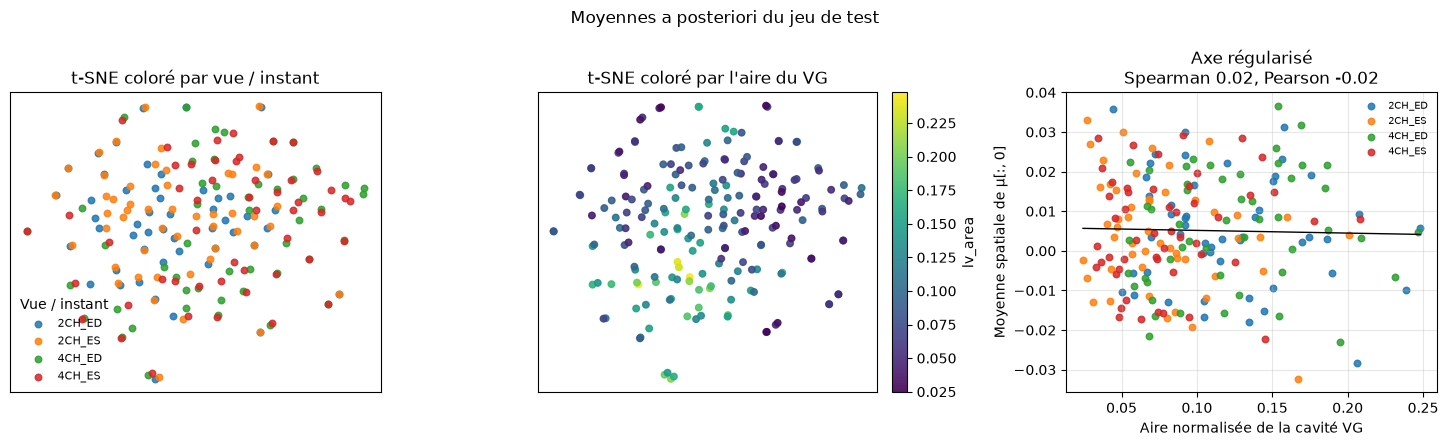

In [14]:
mu_np = test_pred["mu"].numpy()
flat = mu_np.reshape(mu_np.shape[0], -1)
print(f"Matrice passée à t-SNE : {flat.shape} = (images de test, coefficients latents).")
embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=SEED,
).fit_transform(flat)
print(f"Projection t-SNE : {embedding.shape}")

z0 = test_pred["mu"][:, 0].mean(dim=(1, 2)).numpy()
lv_area = np.asarray(test_pred["lv_area"], dtype=np.float64)
spearman_rho, spearman_p = spearmanr(z0, lv_area)
pearson_r, pearson_p = pearsonr(z0, lv_area)
print(f"Spearman(z0, lv_area) = {spearman_rho:.3f}  (p = {spearman_p:.3g})")
print(f"Pearson(z0, lv_area)  = {pearson_r:.3f}  (p = {pearson_p:.3g})")

within_view = {}
for view in ("2CH", "4CH"):
    selected = test_pred["view"] == view
    rho, p_value = spearmanr(z0[selected], lv_area[selected])
    within_view[view] = {
        "spearman": float(rho),
        "pvalue": float(p_value),
        "n": int(selected.sum()),
    }
    print(f"Spearman dans la vue {view} (n = {int(selected.sum())}) : {rho:.3f}  (p = {p_value:.3g})")

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.5))
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[0].scatter(
        embedding[selected, 0],
        embedding[selected, 1],
        s=22,
        alpha=0.85,
        label=view_instant,
    )
axes[0].legend(frameon=False, title="Vue / instant", fontsize=8)
axes[0].set_title("t-SNE coloré par vue / instant")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].grid(True, color="0.9")

area_scatter = axes[1].scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=lv_area,
    cmap="viridis",
    s=22,
    alpha=0.9,
)
axes[1].set_title("t-SNE coloré par l'aire du VG")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].grid(True, color="0.9")
fig.colorbar(area_scatter, ax=axes[1], fraction=0.046, pad=0.04, label="lv_area")

for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[2].scatter(lv_area[selected], z0[selected], s=22, alpha=0.85, label=view_instant)
order = np.argsort(lv_area)
slope, intercept = np.polyfit(lv_area, z0, 1)
axes[2].plot(lv_area[order], slope * lv_area[order] + intercept, color="black", lw=1.0)
axes[2].set_xlabel("Aire normalisée de la cavité VG")
axes[2].set_ylabel("Moyenne spatiale de μ[:, 0]")
axes[2].set_title(f"Axe régularisé\nSpearman {spearman_rho:.2f}, Pearson {pearson_r:.2f}")
axes[2].grid(True, alpha=0.3)
axes[2].legend(frameon=False, fontsize=7)
fig.suptitle("Moyennes a posteriori du jeu de test")
fig.tight_layout()
plt.show()


### Interpolation ED → ES

On prend, dans le jeu de test, la télédiastole et la télésystole de `patient0010` en vue 4 cavités. Les deux moyennes latentes sont interpolées linéairement, puis chaque pas est décodé. Un trajet continu, où la cavité se contracte sans casser le secteur échographique, est la propriété de continuité du VAE, contrôlée sur une paire physiologiquement ordonnée.

L'animation fait l'aller puis le retour. Elle est écrite dans `artifacts/exp3_interp_ED_ES.gif`. La bande statique ci-dessous est la version lisible dans le notebook.


patient0010 4CH : interpolation de μ_ED vers μ_ES, 16 pas.
lv_area ED 0.0684, ES 0.0483.
GIF aller-retour enregistré dans artifacts/exp3_interp_ED_ES.gif.


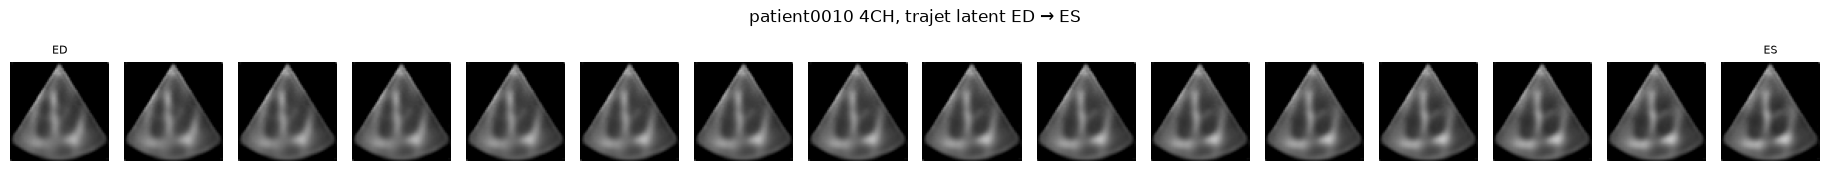

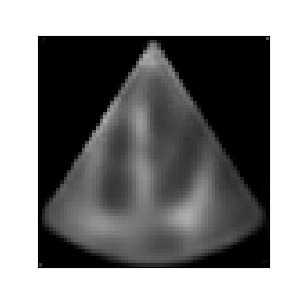

In [15]:
def index_of(dataset, patient, view, instant):
    for index, record in enumerate(dataset.records):
        if (
            record["patient"] == patient
            and record["view"] == view
            and record["instant"] == instant
        ):
            return index
    raise KeyError((patient, view, instant))


def encode_mu(net, dataset, index):
    image = dataset[index]["image"][None].to(device)
    with torch.no_grad():
        mu, _ = net.encode(image)
    return mu


def interpolate(net, z_start, z_end, steps):
    weights = torch.linspace(0, 1, steps, device=z_start.device)
    codes = torch.cat([torch.lerp(z_start, z_end, float(weight)) for weight in weights], dim=0)
    with torch.no_grad():
        frames = net.decode(codes)[:, 0].cpu().clamp(0, 1).numpy()
    return frames


def save_gif(frames, path, fps=8):
    fig, ax = plt.subplots(figsize=(3, 3))
    shown = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])

    def update(frame_index):
        shown.set_data(frames[frame_index])
        return [shown]

    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps, blit=True)
    animation.save(path, writer="pillow", fps=fps)
    plt.close(fig)


gif_patient, gif_view = "patient0010", "4CH"
ed_index = index_of(test_dataset, gif_patient, gif_view, "ED")
es_index = index_of(test_dataset, gif_patient, gif_view, "ES")

z_ed = encode_mu(model, test_dataset, ed_index)
z_es = encode_mu(model, test_dataset, es_index)
forward = interpolate(model, z_ed, z_es, steps=16)
cycle = np.concatenate([forward, forward[-2:0:-1]], axis=0)

gif_path = ARTIFACT_DIR / "exp3_interp_ED_ES.gif"
save_gif(cycle, gif_path, fps=8)
print(f"{gif_patient} {gif_view} : interpolation de μ_ED vers μ_ES, {forward.shape[0]} pas.")
print(
    f"lv_area ED {test_dataset[ed_index]['lv_area']:.4f}, "
    f"ES {test_dataset[es_index]['lv_area']:.4f}."
)
print(f"GIF aller-retour enregistré dans {gif_path}.")

fig, axes = plt.subplots(1, forward.shape[0], figsize=(1.15 * forward.shape[0], 1.8))
for ax, frame in zip(axes, forward):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0].set_title("ED", fontsize=8)
axes[-1].set_title("ES", fontsize=8)
fig.suptitle(f"{gif_patient} {gif_view}, trajet latent ED → ES")
fig.tight_layout()
plt.show()

display(Image(filename=str(gif_path)))


In [16]:
results_exp3 = {
    "experiment": 3,
    "seed": SEED,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_loss": "0.7*weighted_l1+0.3*ssim",
    "heart_weight_map": "1 + 2 * (label > 0)",
    "attribute": "lv cavity area, label == 1",
    "channels": list(CHANNELS),
    "latent_shape": list(LATENT_SHAPE),
    "n_params": N_PARAMS,
    "optimizer": "AdamW",
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "best_val": history["best_val"],
    "seconds": history["seconds"],
    "seconds_per_epoch": history["seconds"] / history["epochs"],
    "history": {
        key: value
        for key, value in history.items()
        if key != "config"
    },
    "test": {
        "n": len(test_dataset),
        "mse_mean": exp3_mse_mean,
        "mse_std": exp3_mse_std,
        "mae_mean": exp3_mae_mean,
        "mae_std": exp3_mae_std,
        "psnr_mean": exp3_psnr_mean,
        "psnr_std": exp3_psnr_std,
        "ssim_mean": exp3_ssim_mean,
        "ssim_std": exp3_ssim_std,
        "heart_mse_mean": exp3_heart_mean,
        "heart_mse_std": exp3_heart_std,
        "background_mse_mean": exp3_background_mean,
        "background_mse_std": exp3_background_std,
        "per_view_instant": per_view_instant,
    },
    "latent_attribute": {
        "spearman_mu0_lv_area": float(spearman_rho),
        "spearman_pvalue": float(spearman_p),
        "pearson_mu0_lv_area": float(pearson_r),
        "pearson_pvalue": float(pearson_p),
        "within_view": within_view,
        "n": int(len(z0)),
    },
    "interpolation_gif": str(gif_path),
    "comparison": comparison_columns,
    "experiment_1_recomputed_mse": exp1_recomputed_mse,
}

results_path = ARTIFACT_DIR / "results_exp3.json"
results_path.write_text(
    json.dumps(results_exp3, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
print(f"Résultats écrits dans {results_path}.")
print(
    f"Expérience 3 — meilleure époque {history['best_epoch']}/{history['epochs']}, "
    f"MSE test {exp3_mse_mean:.5f}, PSNR {exp3_psnr_mean:.2f} dB, "
    f"SSIM {exp3_ssim_mean:.3f}, MSE cœur {exp3_heart_mean:.5f}, "
    f"durée {history['seconds'] / 60:.1f} min."
)


Résultats écrits dans artifacts/results_exp3.json.
Expérience 3 — meilleure époque 20/20, MSE test 0.01024, PSNR 20.84 dB, SSIM 0.703, MSE cœur 0.01298, durée 12.6 min.


## Analyse critique

Sur les 200 images de test, l'expérience 3 atteint une MSE de 0.01024 ± 0.01042, un PSNR de 20.84 ± 2.48 dB et un SSIM de 0.703 ± 0.052. La MSE sur le cœur est 0.01298 ± 0.01028, celle sur le fond 0.00938 ± 0.01090. L'entraînement a duré 12.6 min (37.9 s par époque, 478 417 paramètres). Le minimum de la perte de validation, à partir de l'époque 5, est l'époque 20.

Ces chiffres séparent les deux échecs des runs précédents. L'expérience 2, dont l'objectif est une MSE, descend à 0.00765 et 21.70 dB, et le SSIM tombe à 0.445 : une erreur quadratique est minimale pour une image localement moyennée, donc pour un speckle effacé. L'expérience 3 reste à la MSE de l'expérience 1 (0.01024) et porte le SSIM à 0.703, au-dessus des 0.622 de la L1. Le terme 0.7 L1 pénalise l'écart d'intensité pixel à pixel. Le terme 0.3 SSIM, calculé sur la reconstruction bornée à [0, 1], pénalise la perte de contraste local. Le nombre de paramètres est celui de l'expérience 1 (478 417 contre 473 649) : le SSIM monte sans reprendre la largeur qui, dans l'expérience 2, accompagnait sa chute. Sur la grille de test, le cône et les cavités restent lisibles, et l'erreur absolue se concentre sur le speckle et les bords. Ce sont les hautes fréquences qu'une MSE aurait lissées, et ce sont elles qui maintiennent la MSE au niveau de l'expérience 1. Le PSNR, 20.84 dB, reste sous les 20.97 dB de l'expérience 1 et les 21.70 dB de l'expérience 2. La pente de fin d'apprentissage est trop faible pour refermer l'écart de MSE avec l'expérience 2, qui vaut 0.0026 : de l'époque 14 à l'époque 20, la MSE de validation passe de 0.00857 à 0.00836.

Le poids anatomique déplace une partie de cette erreur. Le cœur occupe 24,5 % des pixels d'entraînement. Avec W = 3 sur le masque, il porte près de la moitié de la L1. La MSE cœur passe de 0.01511, recalculée pour l'expérience 1 avec `vae_final.pth` et le même code, à 0.01298. La MSE de fond remonte de 0.00871 à 0.00938. Le cœur reste plus difficile que le fond, et il reste au-dessus de l'expérience 2 (0.01073). Cette dernière minimise le carré avec un décodeur quatre fois plus large. Le masque est une annotation que les pertes des expériences 1 et 2 ne voyaient pas. Même avec cette supervision, la fidélité quadratique sur le cœur ne rattrape pas le modèle MSE. Le MAE global, 0.061 contre 0.057 et 0.055, suit le même mouvement : l'objectif n'est pas le MAE uniforme, il concentre la L1 sur le cœur et laisse au speckle une erreur absolue que le SSIM tolère mieux que la MSE.

Le temps suit la taille du réseau, en deçà du rapport des paramètres. L'expérience 2 a pris 30.5 min (91.5 s par époque, 1 888 449 paramètres). L'expérience 3 a pris 12.6 min, un facteur 2,4, pour un réseau 3,9 fois plus petit. L'écart entre ces deux rapports vient du SSIM, fenêtre 7, calculé à chaque pas. Un facteur 3 aurait demandé environ 10 min. Les 8 min visées au départ correspondent aux ablations de 8 époques de l'expérience 1, pas à 20 époques de cette perte. Par époque, ce run (37.9 s) est plus court que le VAE final de l'expérience 1 (64.3 s, 26.8 min sur 25 époques). Le cosinus a tenu la fin d'apprentissage : là où la validation de l'expérience 2 remontait à l'époque 20, la perte totale de validation descend jusqu'à la dernière époque. Le SSIM de validation, après un creux à l'époque 9 (0.633), se stabilise vers 0.717. La KL de validation passe de 520 à l'époque 1 à un plateau proche de 146. Le postérieur reste loin d'un effondrement.

La coordonnée régularisée ne porte pas l'aire de la cavité. L_attr vaut 0.98 à l'époque 1 et 1.00 à l'époque 20. C'est l'écart moyen d'un tanh proche de zéro à des cibles ±1 : les différences de z₀ restent trop petites pour ordonner les aires, et le terme ne quitte pas ce régime. À la fin, γ L_attr ≈ 0.001, β KL ≈ 0.015 et L_recon ≈ 0.13. Le terme d'attribut est le plus petit des trois, d'un ordre de grandeur sous la KL. Sur le test, Spearman(z₀, lv_area) = 0.023 (p = 0.75) et Pearson = −0.024. À l'intérieur de chaque vue, les corrélations restent non significatives (2CH : −0.13, p = 0.18 ; 4CH : 0.18, p = 0.07). z₀ occupe un intervalle de quelques centièmes, donc δ = 5 ne pousse pas le tanh jusqu'à ±1. Le t-SNE des 512 coefficients mélange les quatre couples vue / instant, et la couleur par aire ne trace pas de gradient. L'interpolation μ_ED → μ_ES de patient0010 en 4CH (aires 0.068 et 0.048) garde un secteur continu, avec une contraction légère et un speckle moyenné. La continuité du décodeur est acquise. La texture échographique ne l'est pas.

Limites. Une graine, vingt époques, deux instants par vue. Le trajet latent teste une interpolation, il ne modélise pas le cycle cardiaque. Plusieurs choix bougent ensemble par rapport à chaque expérience précédente : taille du latent, forme de la reconstruction, masque dans la perte, AdamW, calendrier. Le saut de SSIM se comprend par le terme qui l'optimise. Il ne s'attribue pas au seul passage de 4 à 8 canaux latents. Le masque n'entre pas dans le réseau. Il reste une annotation supplémentaire pendant l'apprentissage.
